In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
from datetime import datetime

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths for train and test sets
train_path = '/kaggle/working/PCOSGen-train/train'
test_path = '/kaggle/working/PCOSGen-train/test'

# Preprocessing transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(40),
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop(224),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

# Load datasets
train_dataset = datasets.ImageFolder(train_path, transform=data_transforms['train'])
test_dataset = datasets.ImageFolder(test_path, transform=data_transforms['test'])

# DataLoaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Load pre-trained VGG16 model
vgg = models.vgg16(pretrained=True)

# Freeze the VGG layers
for param in vgg.parameters():
    param.requires_grad = False

# Modify the classifier layer to match the number of classes
num_classes = len(train_dataset.classes)
vgg.classifier[6] = nn.Linear(vgg.classifier[6].in_features, num_classes)

# Move the model to GPU if available
vgg = vgg.to(device)

# ============================================================
# Dice Loss + Combined CrossEntropy + Dice Loss
# ============================================================
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()
        intersection = (probs * targets_one_hot).sum(dim=0)
        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)
        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)
        return 1. - dice_score.mean()


class CombinedLoss(nn.Module):
    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice


criterion = CombinedLoss(num_classes=num_classes, ce_weight=0.5, dice_weight=0.5)
optimizer = optim.Adam(vgg.classifier[6].parameters())

# Training config
num_epochs = 50
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
train_ce_losses, train_dice_losses = [], []
val_ce_losses, val_dice_losses = [], []

# Function to calculate accuracy
def calculate_accuracy(y_pred, y_true):
    _, predicted = torch.max(y_pred, 1)
    correct = (predicted == y_true).sum().item()
    return correct / len(y_true)

# Model saving + early stopping config
best_val_accuracy = 0.0
model_save_path = 'best_vgg_model.pth'
patience = 8
epochs_no_improve = 0

# Start training
start = datetime.now()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 210MB/s] 


Epoch 1/50


Training: 100%|██████████| 25/25 [00:29<00:00,  1.19s/it]


Train Loss: 0.5517 (CE: 0.6232, Dice: 0.4801), Train Accuracy: 0.6728


Validating: 100%|██████████| 12/12 [00:11<00:00,  1.02it/s]


Validation Loss: 0.4960 (CE: 0.4121, Dice: 0.5798), Validation Accuracy: 0.7652

  -> Model saved at epoch 1 with validation accuracy 0.7652
Epoch 2/50


...

Validation Loss: 0.4275 (CE: 0.3136, Dice: 0.5414), Validation Accuracy: 0.8429

  -> No improvement for 7/8 epochs
Epoch 17/50


Training: 100%|██████████| 25/25 [00:30<00:00,  1.21s/it]


Train Loss: 0.4735 (CE: 0.5372, Dice: 0.4097), Train Accuracy: 0.7194


Validating: 100%|██████████| 12/12 [00:12<00:00,  1.01s/it]


Validation Loss: 0.4602 (CE: 0.3691, Dice: 0.5514), Validation Accuracy: 0.8322

  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 17. Best Val Accuracy: 0.8884
Training completed in time:  0:17:08.952460
Best model loaded with validation accuracy: 0.8884


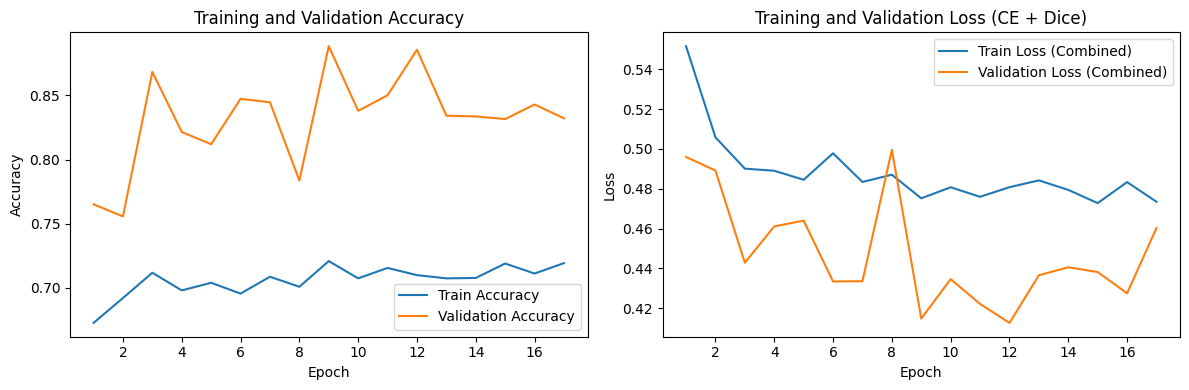

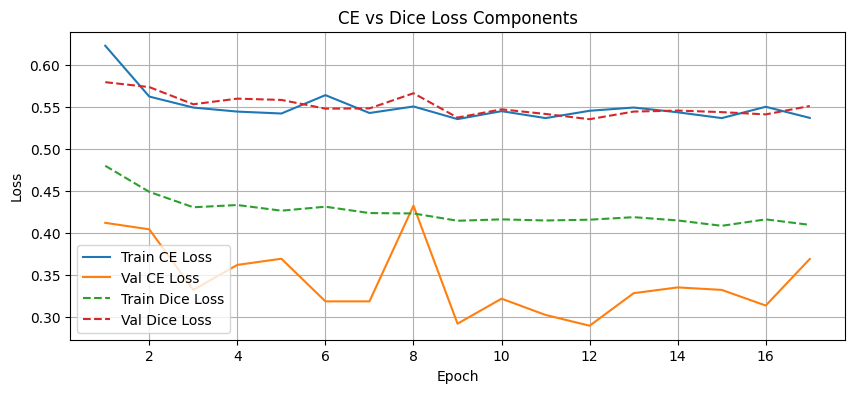

Test accuracy: 0.8884


In [5]:
for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    vgg.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0
    running_accuracy = 0.0

    for inputs, labels in tqdm(train_loader, desc='Training'):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs = vgg(inputs)
        loss, ce, dice = criterion(outputs, labels)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()
        running_accuracy += calculate_accuracy(outputs, labels)

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_ce = running_ce / len(train_loader)
    epoch_train_dice = running_dice / len(train_loader)
    epoch_train_accuracy = running_accuracy / len(train_loader)

    train_losses.append(epoch_train_loss)
    train_ce_losses.append(epoch_train_ce)
    train_dice_losses.append(epoch_train_dice)
    train_accuracies.append(epoch_train_accuracy)

    print(f"Train Loss: {epoch_train_loss:.4f} (CE: {epoch_train_ce:.4f}, Dice: {epoch_train_dice:.4f}), "
          f"Train Accuracy: {epoch_train_accuracy:.4f}")

    # Validation phase
    vgg.eval()
    val_loss = 0.0
    val_ce = 0.0
    val_dice = 0.0
    val_accuracy = 0.0

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc='Validating'):
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = vgg(inputs)
            loss, ce, dice = criterion(outputs, labels)

            val_loss += loss.item()
            val_ce += ce.item()
            val_dice += dice.item()
            val_accuracy += calculate_accuracy(outputs, labels)

    epoch_val_loss = val_loss / len(test_loader)
    epoch_val_ce = val_ce / len(test_loader)
    epoch_val_dice = val_dice / len(test_loader)
    epoch_val_accuracy = val_accuracy / len(test_loader)

    val_losses.append(epoch_val_loss)
    val_ce_losses.append(epoch_val_ce)
    val_dice_losses.append(epoch_val_dice)
    val_accuracies.append(epoch_val_accuracy)

    print(f"Validation Loss: {epoch_val_loss:.4f} (CE: {epoch_val_ce:.4f}, Dice: {epoch_val_dice:.4f}), "
          f"Validation Accuracy: {epoch_val_accuracy:.4f}\n")

    # Save the model if validation accuracy improves, else track patience
    if epoch_val_accuracy > best_val_accuracy:
        best_val_accuracy = epoch_val_accuracy
        epochs_no_improve = 0
        torch.save(vgg.state_dict(), model_save_path)
        print(f"  -> Model saved at epoch {epoch+1} with validation accuracy {best_val_accuracy:.4f}")
    else:
        epochs_no_improve += 1
        print(f"  -> No improvement for {epochs_no_improve}/{patience} epochs")

    # Early stopping
    if epochs_no_improve >= patience:
        print(f"\nEarly stopping triggered at epoch {epoch+1}. Best Val Accuracy: {best_val_accuracy:.4f}")
        break

duration = datetime.now() - start
print("Training completed in time: ", duration)

# Load the best model after training
vgg.load_state_dict(torch.load(model_save_path))
print(f"Best model loaded with validation accuracy: {best_val_accuracy:.4f}")

# Plotting accuracy and loss
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracies, label='Train Accuracy')
plt.plot(epochs_range, val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot (combined)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
plt.plot(epochs_range, val_losses, label='Validation Loss (Combined)')
plt.title('Training and Validation Loss (CE + Dice)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Plot CE vs Dice components separately
plt.figure(figsize=(10, 4))
plt.plot(epochs_range, train_ce_losses, label='Train CE Loss')
plt.plot(epochs_range, val_ce_losses, label='Val CE Loss')
plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CE vs Dice Loss Components')
plt.legend()
plt.grid(True)
plt.show()

# Testing the model (best checkpoint)
vgg.eval()
test_accuracy = 0.0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = vgg(inputs)
        test_accuracy += calculate_accuracy(outputs, labels)

test_accuracy /= len(test_loader)
print(f'Test accuracy: {test_accuracy:.4f}')

Precision (weighted): 0.9056
Recall (weighted):    0.9033
F1-score (weighted):  0.8990

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.90      0.98      0.94      1052
  Appears normal       0.93      0.71      0.81       416

        accuracy                           0.90      1468
       macro avg       0.91      0.85      0.87      1468
    weighted avg       0.91      0.90      0.90      1468

Confusion Matrix:
[[1030   22]
 [ 120  296]]


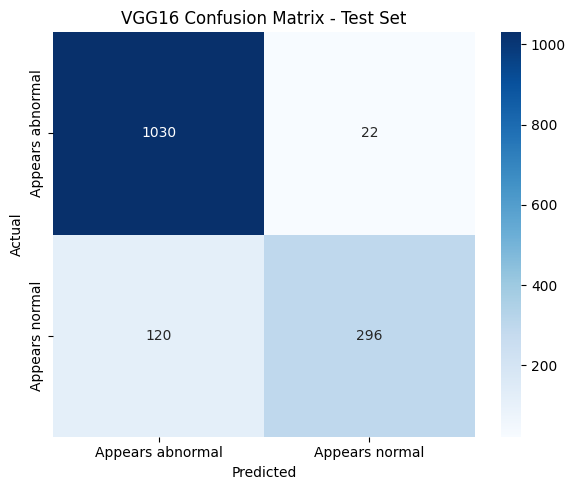


Summary:
Best Val Accuracy during training: 0.8884
Final Test Accuracy: 0.8884
Final Test Precision: 0.9056, Recall: 0.9033, F1-score: 0.8990


In [8]:
# ============================================================
# ADDITIONAL EVALUATION METRICS
# (uses the already-trained `vgg` model, `test_loader`, and
#  `device` from the cells above — nothing above is changed)
# ============================================================

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

vgg.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = vgg(inputs)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

class_names = test_dataset.classes

# Precision, Recall, F1-score (weighted, accounts for class imbalance)
precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted):    {recall:.4f}")
print(f"F1-score (weighted):  {f1:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(all_labels, all_predictions, target_names=class_names, zero_division=0))

# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('VGG16 Confusion Matrix - Test Set')
plt.tight_layout()
plt.show()

print(f'\nSummary:')
print(f'Best Val Accuracy during training: {best_val_accuracy:.4f}')
print(f'Final Test Accuracy: {test_accuracy:.4f}')
print(f'Final Test Precision: {precision:.4f}, Recall: {recall:.4f}, F1-score: {f1:.4f}')